# 01 · Why interactive? Plotly Express

**Goal:** go from a static chart to an interactive one, learn the interactions you get for free, and customize Plotly figures.

> A static figure answers the question you chose in advance. An interactive one lets readers
> ask their own: zooming into a region, filtering to a subgroup, or hovering to see the values.

We use the **Gapminder** dataset that ships with Plotly: life expectancy, GDP per capita and population for 142 countries, every five years from 1952 to 2007.

In [2]:
import pandas as pd
import plotly.express as px

gap = px.data.gapminder()
gap.head()

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4


## 1. Start from what you know: a static chart

This is the kind of chart from Part 1. It's fine for the question "is wealth related to life expectancy?" But try answering: **which country is the big dot at the bottom of the Americas?**

In [3]:
import matplotlib.pyplot as plt

In [4]:
g07 = gap.query("year == 2007")

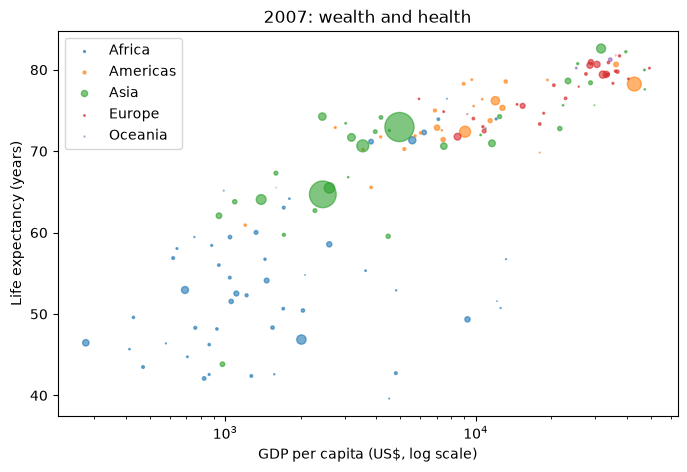

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

for continent, d in g07.groupby("continent"):
    ax.scatter(d.gdpPercap, 
               d.lifeExp, 
               s=d["pop"] / 3e6, 
               alpha=0.6, 
               label=continent)

ax.set_xscale("log")
ax.set(xlabel="GDP per capita (US$, log scale)", 
       ylabel="Life expectancy (years)",
       title="2007: wealth and health")
ax.legend(markerscale=0.3)

plt.show()

## 2. The same chart in Plotly Express

One function call. Notice that the arguments name **data columns**, not arrays.

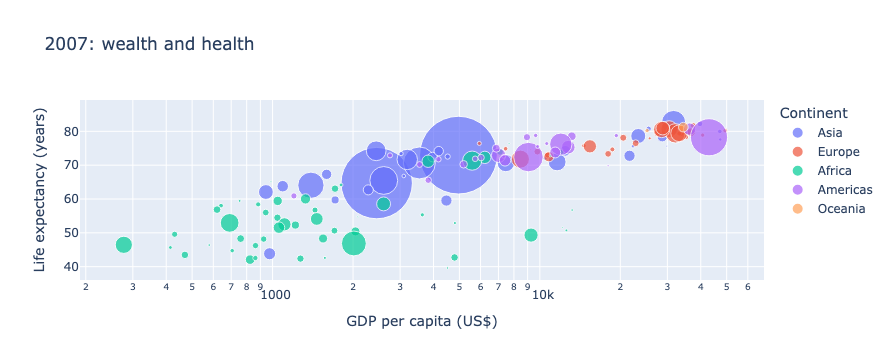

In [6]:
fig = px.scatter(
    g07,
    x="gdpPercap", 
    y="lifeExp",
    size="pop", 
    color="continent",
    hover_name="country",
    log_x=True, 
    size_max=55,
    labels={"gdpPercap": "GDP per capita (US$)", 
            "lifeExp": "Life expectancy (years)",
            "pop": "Population", 
            "continent": "Continent"},
    title="2007: wealth and health",
)
fig

### Interactions you get for free — try each one

| Do this | What happens |
| --- | --- |
| Hover a dot | Tooltip with the underlying values |
| Drag a box | Zoom into that region |
| Double-click the plot | Reset zoom |
| Click a legend entry | Hide/show that group |
| Double-click a legend entry | Show **only** that group |
| Camera icon (top right) | Download as PNG |

**For consideration:** which of these change what a reader can learn from the chart?

## 3. Controlling the hover

The tooltip is your main channel for "underlying values". Control what's in it and how it's formatted.

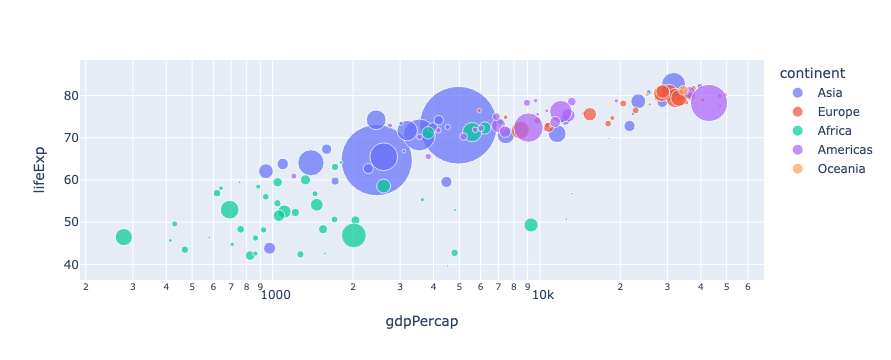

In [7]:
fig = px.scatter(
    g07, 
    x="gdpPercap", 
    y="lifeExp", 
    size="pop", 
    color="continent",
    hover_name="country", 
    log_x=True, 
    size_max=55,
    hover_data={
        "continent": False,          # already shown by color: hide it
        "pop": ":,.0f",              # thousands separators
        "gdpPercap": ":$,.0f",       # currency
        "lifeExp": ":.1f",
        "iso_alpha": True,           # add a column that isn't plotted
    },
)
fig

For full control use a `hovertemplate`. `%{x}`, `%{y}` and `%{customdata[i]}` pull values; `<extra></extra>` removes the trace-name box.

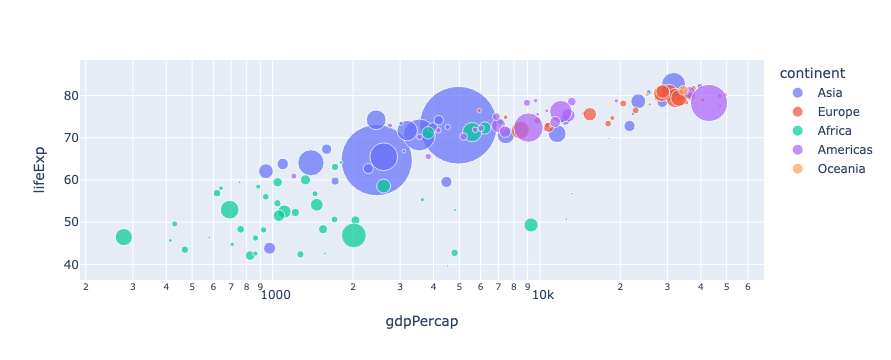

In [8]:
fig = px.scatter(
    g07, 
    x="gdpPercap", 
    y="lifeExp", 
    size="pop", 
    color="continent",
    log_x=True, 
    size_max=55, 
    custom_data=["country", "pop"],
)
fig.update_traces(
    hovertemplate="<b>%{customdata[0]}</b><br>"
                  "GDP per capita: $%{x:,.0f}<br>"
                  "Life expectancy: %{y:.1f} years<br>"
                  "Population: %{customdata[1]:,.0f}<extra></extra>"
)
fig

## 4. Small multiples and time series

`facet_col` / `facet_row` split the data into panels. Zoom in one panel and the shared axes follow.

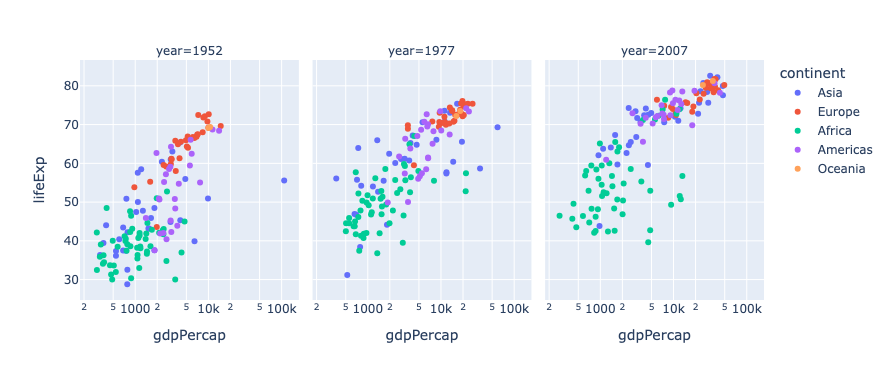

In [9]:
px.scatter(
    gap.query("year in [1952, 1977, 2007]"),
    x="gdpPercap", 
    y="lifeExp", 
    color="continent", 
    hover_name="country",
    facet_col="year", 
    log_x=True, 
    height=380,
)

Time series benefit from a **range slider** and a **unified hover** that reads every series at one date. The `stocks` dataset holds six tech stocks, each normalized to 1.0 on the first day of 2018.

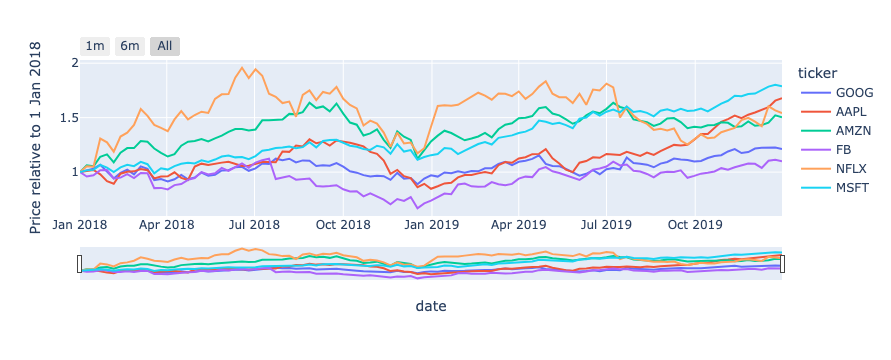

In [10]:
stocks = px.data.stocks()
stocks_long = stocks.melt(id_vars="date", var_name="ticker", value_name="price")

fig = px.line(stocks_long, 
              x="date", 
              y="price", 
              color="ticker",
              labels={"price": "Price relative to 1 Jan 2018"})
fig.update_layout(hovermode="x unified")
fig.update_xaxes(
    rangeslider_visible=True,
    rangeselector=dict(buttons=[
        dict(count=1, label="1m", step="month", stepmode="backward"),
        dict(count=6, label="6m", step="month", stepmode="backward"),
        dict(step="all", label="All"),
    ]),
)
fig

## 5. Animation

`animation_frame` adds a play button and slider. Fix the axis ranges so the frame doesn't jump.

**Caveat:** animation is great for a presentation and poor for comparison. Readers can't hold 1952 in their head while looking at 2007. Pair it with a static view when the comparison matters.

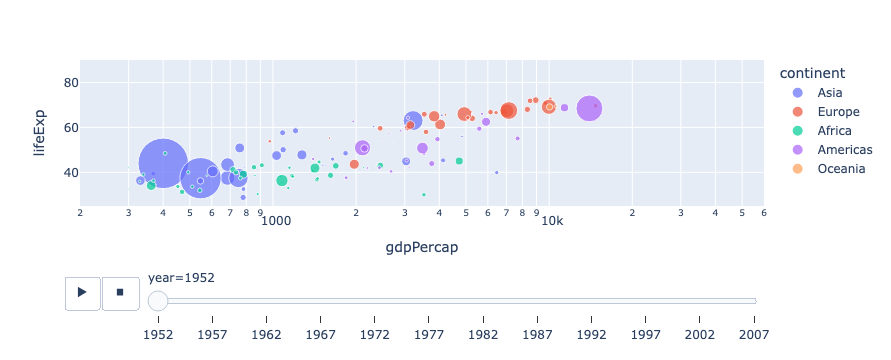

In [11]:
px.scatter(
    gap, 
    x="gdpPercap", 
    y="lifeExp", 
    size="pop", 
    color="continent",
    hover_name="country", 
    log_x=True, 
    size_max=55,
    animation_frame="year", 
    animation_group="country",
    range_x=[200, 60_000], 
    range_y=[25, 90],
)

## 6. Under the hood: figures are data

Every Plotly Express call returns a `go.Figure`: a tree of **traces** (the data) and **layout** (everything else). You can tweak it with `update_*` methods or add elements with `add_*`.

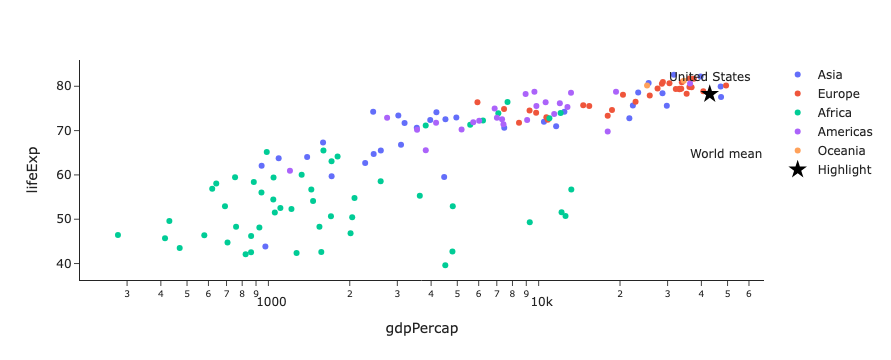

In [12]:
import plotly.graph_objects as go

fig = px.scatter(g07, 
                 x="gdpPercap", 
                 y="lifeExp", 
                 color="continent",
                 hover_name="country", 
                 log_x=True)
fig.add_hline(y=g07.lifeExp.mean(), 
              line_dash="dot",
              annotation_text="World mean", 
              annotation_position="bottom right")
fig.add_trace(go.Scatter(
    x=g07.query("country == 'United States'").gdpPercap,
    y=g07.query("country == 'United States'").lifeExp,
    mode="markers+text", 
    text=["United States"], 
    textposition="top center",
    marker=dict(size=14, symbol="star", color="black"), 
    name="Highlight",
))
fig.update_layout(template="simple_white", 
                  legend_title_text="")
fig

In [13]:
# The figure is just a dictionary-like structure. Peek at it:
print(fig.layout.xaxis)

layout.XAxis({
    'anchor': 'y', 'domain': [0.0, 1.0], 'title': {'text': 'gdpPercap'}, 'type': 'log'
})


## 7. Performance note

Plotly sends every point to the browser. Up to ~100k points is comfortable; beyond that use `render_mode="webgl"` (automatic above 1,000 points in `px.scatter`) or see notebook 04 for Datashader. For long time series, `plotly-resampler` downsamples on zoom.

---

### ✏️ Exercise: Restaurant tips

The `tips` dataset has one row per restaurant bill. Make a scatter plot of `total_bill` (x)
against `tip` (y) that:

1. colors points by `time` (Lunch/Dinner),
2. makes one panel per `day` (hint: `facet_col`, and `category_orders` to put days in order),
3. shows `size` (party size) and `sex` in the hover, and
4. has readable axis labels.

In [14]:
tips = px.data.tips()
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [15]:
# Your code here

### ✏️ Exercise: Tip percentage by party size

Add a column `tip_pct = tip / total_bill * 100`. Make a **box plot** of `tip_pct` by `size`
with all points shown (`points="all"`) and the day in the hover. Which party size has the widest spread?
Hover the outliers to see them.

In [16]:
# Your code here

### ✏️ Exercise: Stretch: a world map

Make an animated choropleth of life expectancy by country over time with `px.choropleth`,
using `locations="iso_alpha"`, `color="lifeExp"` and `animation_frame="year"`.
Set `range_color=[30, 85]` so colors mean the same thing in every frame.

*The map outlines may be fetched from the internet the first time it renders.*

In [17]:
# Your code here